In [1]:
import os
import numpy as np
import pandas as pd
import uproot as ur

import sys
sys.path.append('../')
utils_path = '/global/cfs/cdirs/alice/blianggi/mypyjetty/pyjetty/pyjetty/alice_analysis/analysis/user/jse/3Dunfolding/'
if utils_path not in sys.path:
    sys.path.insert(0, utils_path)
from jupyter_utils import *

from matplotlib import pyplot as plt
from IPython.display import Image
pd.set_option('display.max_columns', None) # to see all columns of df.head()
pd.set_option('display.max_rows', None)

from matplotlib.patches import PathPatch
from matplotlib.path import Path
from scipy.optimize import curve_fit

# Lauren's colors
L_colors = ['red', 'darkorange', 'limegreen', 'green', 'deepskyblue', 'blue', 'black']
L_linestyles = ['solid', 'dashed']
L_markers = ['s', '^', 'v', 'd', 'P']

In [2]:
# closure test? i.e. there is truth pythia data somewhere to compare to
closure = True

# define binnings
n_bins = 9 #7 # WARNING RooUnfold seg faults if too many bins used
binning_reco = np.array([10, 20, 40, 60, 80, 100, 120, 150, 200, 500]).astype(float)
# binning_reco = np.array([10, 20, 40, 60, 80, 100, 150]).astype(float)
bincenters_reco = get_lin_bincenters(binning_reco)
binwidths_reco = np.array(get_binwidths(binning_reco))

n_bins_true = 9 #7 # WARNING RooUnfold seg faults if too many bins used
binning = np.array([10, 20, 40, 60, 80, 100, 120, 150, 200, 500]).astype(float)
# binning = binning = np.array([5, 10, 20, 40, 60, 80, 100]).astype(float)
bincenters = get_lin_bincenters(binning)
binwidths = np.array(get_binwidths(binning))

labels = "jet $p_T$"

n_iter = 3

In [3]:
len(binning)

10

In [4]:
# file defs, hist imports

f_unfolded = ur.open("/global/cfs/cdirs/alice/blianggi/mypyjetty/storage/jse/rootfiles/unfolding/unfolded1D.root")
# f_preunfold_rm = ur.open("./preunfold_rm1D.root")
# f_preunfold_data = ur.open("./preunfold_fullsimdata.root")
f_preunfold_rm = ur.open("/global/cfs/cdirs/alice/alicepro/hiccup/rstorage/alice/AnalysisResults/blianggi/jse/rms/58919321/response_groomed_forunfolding_merged.root")
# f_unfolded = ur.open("/global/cfs/cdirs/alice/mhwang/cEEC/scripts/unfolding/files/out1D_closure.root")
# f_preunfold_rm = ur.open("/global/cfs/cdirs/alice/mhwang/cEEC/scripts/unfolding/files/mc.root")

# Data, reco [theta_unknown_S]
h1_raw = f_preunfold_rm["jet_match_rec_pur_num_groomed"] #"reco1D"]

# MC, reco [theta0_S]
h1_reco = f_preunfold_rm["jet_match_rec_pur_num_groomed"] #"reco1D"]

# MC, true [theta0_G]
h1_gen = f_preunfold_rm["jet_match_gen_eff_num_groomed"] #"gen1D"]

# Data, true [theta_unknown_G]
if closure:
    h1_true = f_preunfold_rm["jet_match_gen_eff_num_groomed"] #"gen1D"]

h1_unfolded = []
for i in range(1,n_iter+1):
    h1_unfolded.append(f_unfolded["Baysian_Unfolded1Diter{}".format(i)])

#h1_reco_unmatched = f_merged["reco1D_unmatched"]
#h1_gen_unmatched = f_merged["gen1D_unmatched"]


In [5]:
proj = lambda a : a.values()
proj_err = lambda a : a.errors()
proj_err_unf = lambda a : np.sqrt(a.errors()**2 + a.values())

theta0_G = proj(h1_gen)
theta0_S = proj(h1_reco)
theta_unknown_G = proj(h1_true)
theta_unknown_S = proj(h1_raw)

root_setp = ""

values, edges = h1_gen.to_numpy()
print(edges)
print(values)
print(theta0_G)
print()
print(theta0_S)
print()
print(theta_unknown_G)
print(theta_unknown_S)

theta_unfolded = [proj(a) for a in h1_unfolded]

theta0_G_err = proj_err(h1_gen)
theta0_S_err = proj_err(h1_reco)
theta_unknown_G_err = proj_err(h1_true)
theta_unknown_S_err = proj_err(h1_raw)

theta_unfolded_err = [proj_err_unf(a) for a in h1_unfolded]


[ 10.  20.  40.  60.  80. 100. 120. 150. 200. 500.]
[7.03300822e+05 7.21047498e+04 3.87044358e+03 5.76125694e+02
 1.37783569e+02 4.30909328e+01 1.99419287e+01 7.20093827e+00
 1.85381064e+00]
[7.03300822e+05 7.21047498e+04 3.87044358e+03 5.76125694e+02
 1.37783569e+02 4.30909328e+01 1.99419287e+01 7.20093827e+00
 1.85381064e+00]

[5.57195604e+05 4.16105626e+04 2.00059865e+03 2.77852631e+02
 6.12406949e+01 1.76404427e+01 6.52408235e+00 1.53465726e+00
 1.54922685e-01]

[7.03300822e+05 7.21047498e+04 3.87044358e+03 5.76125694e+02
 1.37783569e+02 4.30909328e+01 1.99419287e+01 7.20093827e+00
 1.85381064e+00]
[5.57195604e+05 4.16105626e+04 2.00059865e+03 2.77852631e+02
 6.12406949e+01 1.76404427e+01 6.52408235e+00 1.53465726e+00
 1.54922685e-01]


In [6]:
# print total number of jets
print("######### UNFOLDED JETS #########")
print(binning)
print(theta_unfolded[-1])
print(theta_unfolded_err[-1])
for i in range(len(theta_unfolded)):
    print("\t i={}, {} +/- {}".format(i, np.sum(theta_unfolded[i]), np.sum(theta_unfolded_err[i])))
print("total det jets : {} \n".format(np.sum(theta_unfolded[-1]) ))

print("######### DATA TRUTH JETS #########")
print(binning)
print(theta_unknown_G)
print("total truth jets : {} \n".format(np.sum(theta_unknown_G) ))

print("######### DATA RAW JETS #########")
print(binning_reco)
print(theta_unknown_S)
print("total truth jets : {}".format(np.sum(theta_unknown_S) ))

# TODO propagate error from here to actaul eec calculation
# also why is it exact?!

######### UNFOLDED JETS #########
[ 10.  20.  40.  60.  80. 100. 120. 150. 200. 500.]
[2.51356404e+08 2.65094120e+07 1.88261616e+06 2.84214344e+05
 6.22853920e+04 1.98745641e+04 9.28134668e+03 3.29965147e+03
 8.24875069e+02]
[24864.03020601  8135.67602239  2119.67952626   761.42080933
   338.88962436   183.31291948   126.55992388    75.46768878
    37.9343142 ]
	 i=0, 280251235.0807461 +/- 33169.246987166545
	 i=1, 280156172.6879262 +/- 35284.18381087363
	 i=2, 280128212.17004764 +/- 36642.97103469896
total det jets : 280128212.17004764 

######### DATA TRUTH JETS #########
[ 10.  20.  40.  60.  80. 100. 120. 150. 200. 500.]
[7.03300822e+05 7.21047498e+04 3.87044358e+03 5.76125694e+02
 1.37783569e+02 4.30909328e+01 1.99419287e+01 7.20093827e+00
 1.85381064e+00]
total truth jets : 780062.0124196276 

######### DATA RAW JETS #########
[ 10.  20.  40.  60.  80. 100. 120. 150. 200. 500.]
[5.57195604e+05 4.16105626e+04 2.00059865e+03 2.77852631e+02
 6.12406949e+01 1.76404427e+01 6.52408235e

[ 15.  30.  50.  70.  90. 110. 135. 175. 350.] [7.03300822e+05 7.21047498e+04 3.87044358e+03 5.76125694e+02
 1.37783569e+02 4.30909328e+01 1.99419287e+01 7.20093827e+00
 1.85381064e+00] [ 10.  20.  20.  20.  20.  20.  30.  50. 300.]
[ 15.  30.  50.  70.  90. 110. 135. 175. 350.] [5.57195604e+05 4.16105626e+04 2.00059865e+03 2.77852631e+02
 6.12406949e+01 1.76404427e+01 6.52408235e+00 1.53465726e+00
 1.54922685e-01] [ 10.  20.  20.  20.  20.  20.  30.  50. 300.]


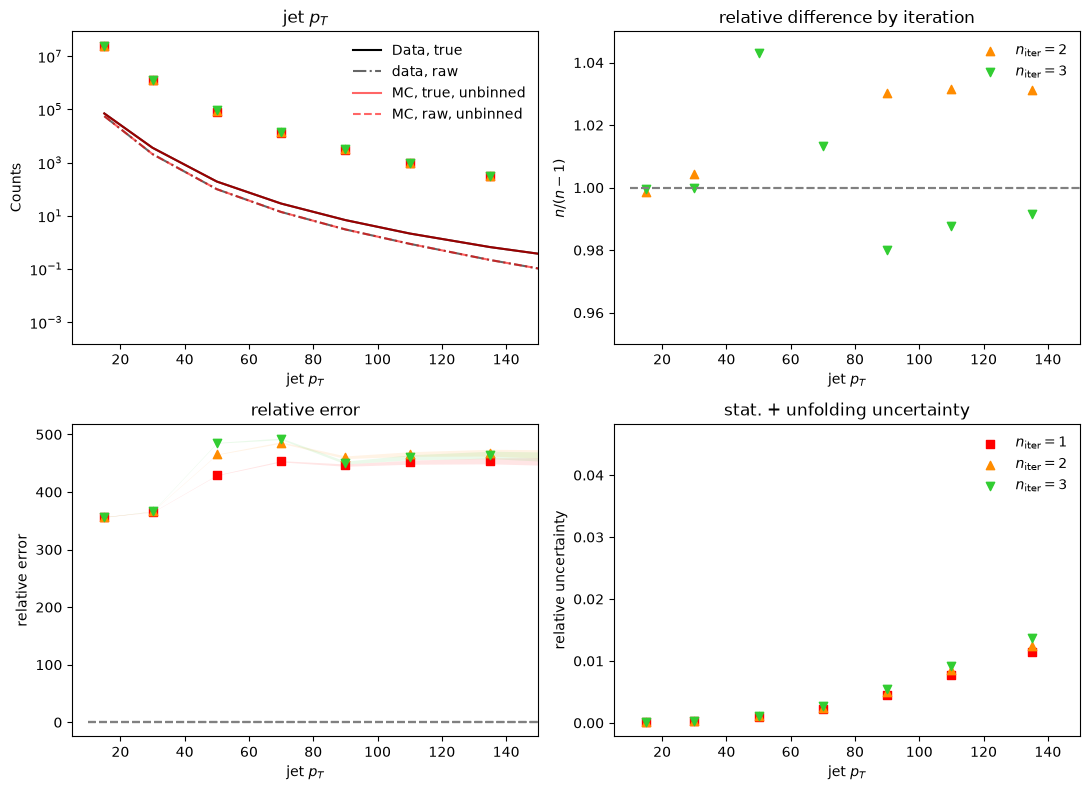

In [7]:
############################## UNFOLDED DISTRIBUTIONS ############################
# EEC distros

it = 3

fig, axes = plt.subplots(2, 2, figsize=(11,8))

pt_lims = [5, 150]

# COL 1: raw jet pt distribution WITH relative error over data, true underneath
ax = axes[0, 0]

print(bincenters, theta_unknown_G, binwidths)
ax.plot(bincenters, theta_unknown_G / binwidths, color='black',label="Data, true")

# comparison with data raw
print(bincenters_reco, theta_unknown_S, binwidths_reco)
ax.plot(bincenters_reco, theta_unknown_S / binwidths_reco, color='black', linestyle='dashdot', alpha=0.6, label="data, raw")

# comparison with MC true, MC det
ax.plot(bincenters, theta0_G / binwidths, color='red', alpha=0.6, label="MC, true, unbinned")

ax.plot(bincenters_reco, theta0_S / binwidths_reco, color='red', alpha=0.6, linestyle='dashed', label="MC, raw, unbinned")

# comparison with published distribution
# norm_hep = 0.2 * np.dot(binwidths, theta0_G) / np.dot(np.diff(hep_compare_x), hep_compare_y[:-1]) # normalize to MC, true
# ax.plot(hep_compare_x, hep_compare_y * norm_hep,color='green',label="published",lw=1)

# comparison with Wenqing's PythiaMC distribution
# norm = (theta_unfolded[-1][3] / h1_compare[2]) * 0.97
# h1_compare_normed = h1_compare * norm
#ax.step(binning[:-1], h1_compare_normed, where="post",color='grey',label="PythiaMC, compare",lw=1)

for iteration in range(it):

    ax.scatter(bincenters, theta_unfolded[iteration] / binwidths,color=L_colors[iteration],marker=L_markers[iteration],lw=1)

    ax.set_ylabel("Counts")
    ax.set_title(labels)
    ax.set_xlabel(labels)
    ax.set_yscale('log')

    ax.legend(frameon=False)

    ax.set_xlim(pt_lims)

# row below with the error
ax = axes[1, 0]

ax.hlines(y=0, xmin=binning[0], xmax=binning[len(binning)-1], color='grey', linestyle='--')

for iteration in range(it):

    yvals, yerrs = get_ratio_safe(theta_unfolded[iteration], theta_unknown_G, \
                                      numerr=theta_unfolded_err[iteration], denomerr=theta_unknown_G_err, filler=1)
    yvals = yvals - 1

    ax.scatter(bincenters, yvals, color=L_colors[iteration],marker=L_markers[iteration],label=f"$n_\mathrm{{iter}}={iteration+1}$",lw=1)

    ax.fill_between(bincenters, yvals-yerrs, yvals+yerrs, alpha=0.1, edgecolor=L_colors[iteration], facecolor=L_colors[iteration], linewidth=0)

    ax.hlines(y=0, xmin=binning[0], xmax=binning[len(binning)-1], color='grey', linestyle='--')
    
    ax.set_title("relative error")
    ax.set_xlabel(labels)
    ax.set_ylabel("relative error")

    #ax.set_ylim([-0.3, 0.3])
    ax.set_xlim(pt_lims)


# COL 2: convergence plot (n / n - 1)
ax = axes[0, 1]

for iteration in range(1,it):

    yvals = safe_divide(theta_unfolded[iteration], theta_unfolded[iteration-1], filler=1)
    ax.scatter(bincenters, yvals, color=L_colors[iteration],marker=L_markers[iteration],label=f"$n_\mathrm{{iter}}={iteration+1}$",lw=1)

    ax.hlines(y=1, xmin=binning[0], xmax=binning[len(binning)-1], color='grey', linestyle='--')

    ax.set_title('relative difference by iteration')
    ax.set_xlabel(labels)
    ax.set_ylabel("$ n / (n-1)$")
    ax.legend(frameon=False)

    ax.set_ylim([0.95, 1.05])
    ax.set_xlim(pt_lims)


# COL 3: statistical error %
ax = axes[1, 1]

for iteration in range(it):
    
    yvals = safe_divide(theta_unfolded_err[iteration], theta_unfolded[iteration])
    ax.scatter(bincenters, yvals, color=L_colors[iteration],marker=L_markers[iteration],label=f"$n_\mathrm{{iter}}={iteration+1}$",lw=1)

    ax.set_title('stat. + unfolding uncertainty')
    ax.set_xlabel(labels)
    ax.set_ylabel("relative uncertainty")
    ax.legend(frameon=False)

    ax.set_xlim(pt_lims)


fig.tight_layout()
plt.show()